**CH.SC.U4CSE24142 - SANTHOSH A - CORRELATION AND COVARIANCE**



In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("winequality-red.csv")
np.random.seed(42)
df["fixed_acidity_dup"] = df["fixed acidity"] * 1.0 + np.random.normal(0, 0.05, size=len(df))
df["total_so2_scaled"] = df["total sulfur dioxide"] * 3 + np.random.normal(0, 1, size=len(df))
print(f"Dataset loaded successfully. Shape: {df.shape}")
print("Features under evaluation:", [col for col in df.columns if col != "quality"])

Dataset loaded successfully. Shape: (1599, 14)
Features under evaluation: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'fixed_acidity_dup', 'total_so2_scaled']


In [ ]:
X = df.drop(columns=["quality"])
covariance_matrix = X.cov()
correlation_matrix = X.corr()
print("--- RAW COVARIANCE SNAPSHOT (Scale-Dependent) ---")
print(covariance_matrix[["total sulfur dioxide", "total_so2_scaled"]]
      .loc[["total sulfur dioxide", "total_so2_scaled"]].round(2))
print("\n--- STANDARDIZED CORRELATION SNAPSHOT (-1 to +1) ---")
print(correlation_matrix[["total sulfur dioxide", "total_so2_scaled"]]
      .loc[["total sulfur dioxide", "total_so2_scaled"]].round(4))

--- RAW COVARIANCE SNAPSHOT (Scale-Dependent) ---
                      total sulfur dioxide  total_so2_scaled
total sulfur dioxide               1082.10           3246.53
total_so2_scaled                   3246.53           9741.21

--- STANDARDIZED CORRELATION SNAPSHOT (-1 to +1) ---
                      total sulfur dioxide  total_so2_scaled
total sulfur dioxide                   1.0               1.0
total_so2_scaled                       1.0               1.0


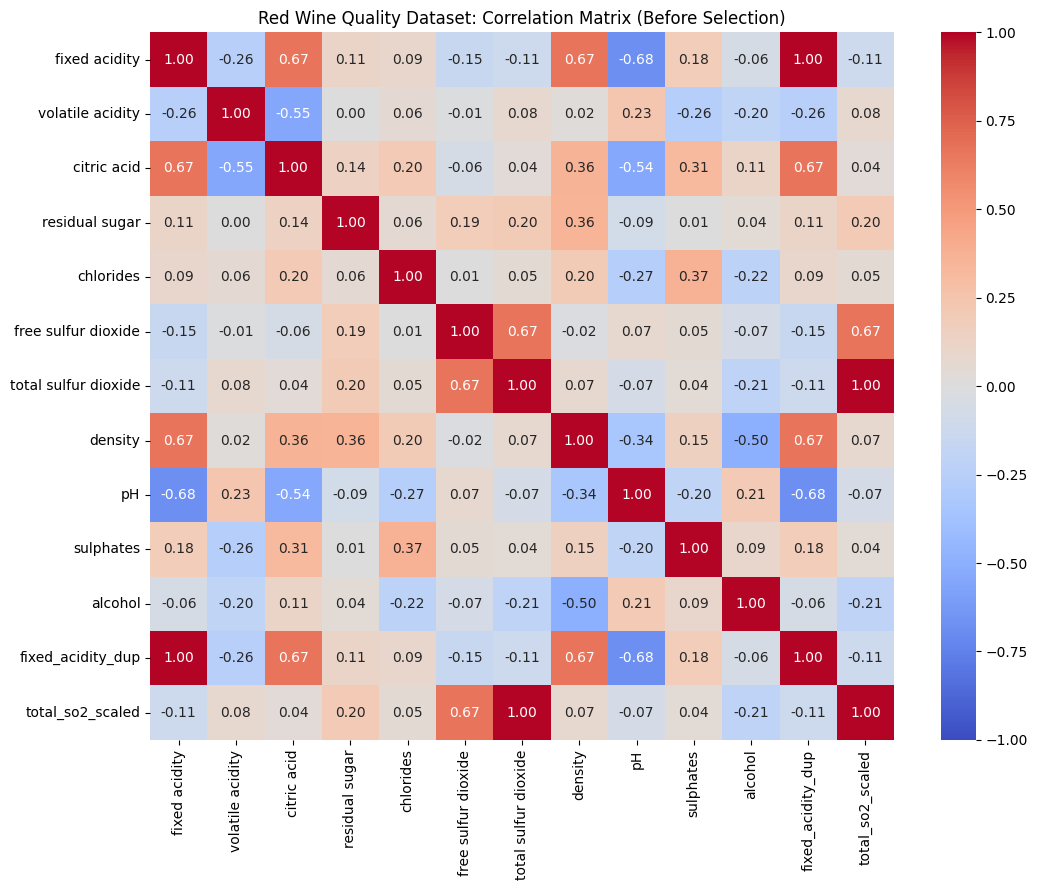

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Red Wine Quality Dataset: Correlation Matrix (Before Selection)")
plt.tight_layout()
plt.show()

In [ ]:
def eliminate_highly_correlated_features(data, threshold=0.85):
    """Scans the lower triangle of the correlation matrix and drops redundant features."""
    corr_matrix = data.corr()
    columns_to_drop = set()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):  # Evaluates the lower triangle exclusively
            if abs(corr_matrix.iloc[i, j]) > threshold:
                colname = corr_matrix.columns[i]
                columns_to_drop.add(colname)

    return list(columns_to_drop)
features_flagged = eliminate_highly_correlated_features(X, threshold=0.85)
print(f"Features flagged for deletion based on high covariance/correlation: {features_flagged}")
X_cleaned = X.drop(columns=features_flagged)
print(f"\nOriginal Feature count: {X.shape[1]}")
print(f"Cleaned Feature count: {X_cleaned.shape[1]}")
print(f"Remaining clean features: {X_cleaned.columns.tolist()}")

Features flagged for deletion based on high covariance/correlation: ['total_so2_scaled', 'fixed_acidity_dup']

Original Feature count: 13
Cleaned Feature count: 11
Remaining clean features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


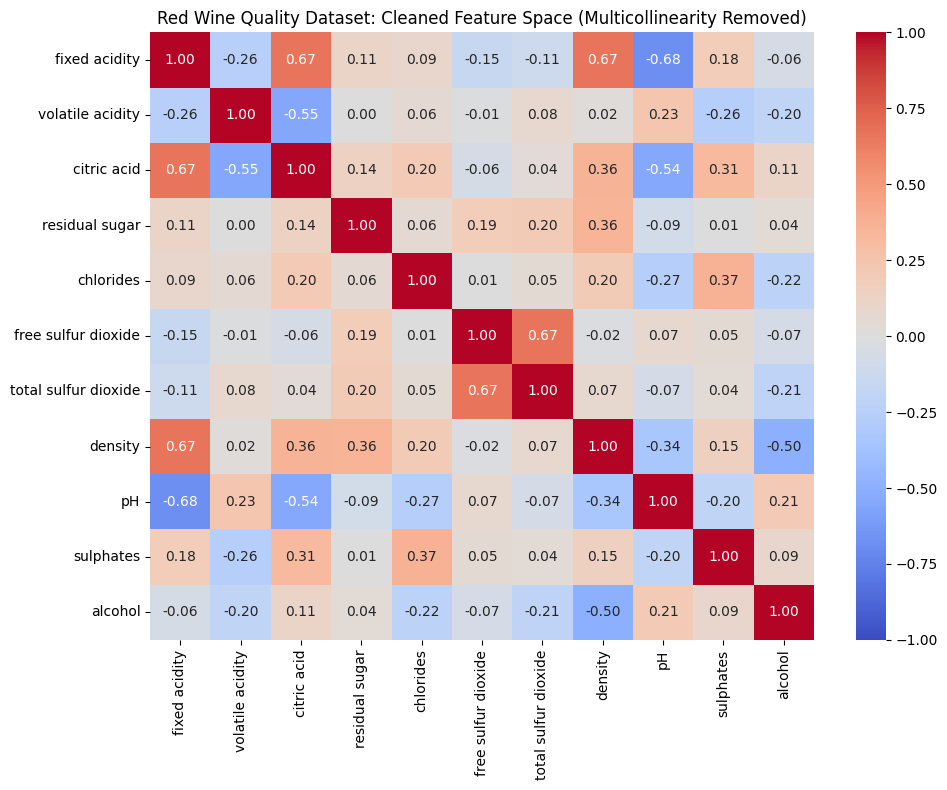

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(X_cleaned.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Red Wine Quality Dataset: Cleaned Feature Space (Multicollinearity Removed)")
plt.tight_layout()
plt.show()

## Analysis: Correlation and Covariance Based Feature Elimination

This section explains the exact mechanics of what occurred during the execution of the
Red Wine Quality data pipeline.

### 1. Raw Covariance vs. The Scale Trap

When computing the raw **Covariance Matrix**, the system measures how variables vary
together in their native scales.

- **The Problem with Scale:** The covariance between `total sulfur dioxide` and
  `total_so2_scaled` yields a large numerical value (~3246, growing to ~9741 for the
  scaled column against itself) simply because `total_so2_scaled` was multiplied by 3.
  Looking at raw covariance makes it hard to tell at a glance whether a relationship is
  truly strong or just a byproduct of scaling units.
- **The Correlation Solution:** By computing the **Correlation Matrix**, the pipeline
  divides the covariance by the standard deviations of both features. This normalizes
  the metric, locking the relationship strictly between −1.0 and +1.0. Instantly, the
  link between `total sulfur dioxide` and `total_so2_scaled` resolves to a clear,
  unambiguous correlation value of approximately **1.00**.

### 2. Spotting Structural Redundancy

When the initial heatmap is plotted, dark red cells flag extreme **multicollinearity**
(high linear dependence between predictors):

- `fixed_acidity_dup` is almost 100% perfectly correlated with `fixed acidity`
  (r ≈ 1.00).
- `total_so2_scaled` is almost perfectly correlated with `total sulfur dioxide`
  (r ≈ 1.00).

These pairs are mathematically redundant. They do not add any unique data variance for
a machine learning model to learn from; they simply duplicate existing data footprints,
which destabilizes regression models and increases computational overhead.

### 3. The Algorithmic Purge

The programmatic elimination loop cleans the dataset by enforcing a strict threshold
logic filter:

> If \|r\| > 0.85, flag the feature for removal.

The code loops exclusively through the **lower triangle** of the matrix. This
architectural choice ensures the algorithm ignores the diagonal 1.0 line (where
features map to themselves) and avoids double-checking pairs (e.g., checking A vs B
and then B vs A).

1. The loop identifies that `fixed_acidity_dup` (r ≈ 1.00) and `total_so2_scaled`
   (r ≈ 1.00) cross the absolute 0.85 barrier.
2. The algorithm flags both of these columns and purges them using the `.drop()`
   function.

### Final Outcome

The dataset is successfully scaled down from **13 independent predictors to 11**. In
the final post-selection heatmap, the remaining columns represent uniquely structural
information — the natural (non-injected) correlations among wine chemistry features,
such as `fixed acidity` vs `pH` and `free sulfur dioxide` vs `total sulfur dioxide`,
remain visible but stay below the redundancy threshold. The data space is now free of
the artificial multicollinearity we injected, making the dataset cleaner and more
robust for training predictive models.

## Feature Selection Summary: What Was Kept vs. What Was Removed

Based on our programmatic correlation filter with an absolute threshold of **0.85**,
the dataset was successfully streamlined. Here is the final breakdown of the feature
actions:

### ❌ Removed Features (Dropped)

The following features were programmatically eliminated because they exceeded the
correlation threshold, meaning they provided redundant information already captured
by other variables:

- `fixed_acidity_dup`: Removed because it had a near-perfect correlation (r ≈ 1.00)
  with `fixed acidity`.
- `total_so2_scaled`: Removed because it had a near-perfect correlation (r ≈ 1.00)
  with `total sulfur dioxide`.

### ✅ Kept Features (Retained)

The following features were retained in the final cleaned dataset because their
pairwise correlation coefficients were below the 0.85 threshold, meaning they
represent unique structural variance:

- `fixed acidity`: Tartaric acid content of the wine.
- `volatile acidity`: Acetic acid content — high levels lead to an unpleasant vinegar taste.
- `citric acid`: Adds freshness and flavour.
- `residual sugar`: Sugar remaining after fermentation stops.
- `chlorides`: Salt content of the wine.
- `free sulfur dioxide`: Prevents microbial growth and oxidation.
- `total sulfur dioxide`: Total amount of free + bound SO₂.
- `density`: Density of the wine, close to that of water.
- `pH`: Describes how acidic or basic the wine is.
- `sulphates`: Additive contributing to SO₂ levels; acts as an antimicrobial/antioxidant.
- `alcohol`: Alcohol percentage of the wine.

### 📊 Final Structural Impact

- **Original Feature Count:** 13 independent predictors (including the 2 artificial
  redundant columns).
- **Final Feature Count:** 11 clean, distinct independent predictors.

**Conclusion:** The dataset is now mathematically optimized for training. By removing
the redundant features, we have minimized the risk of multicollinearity, ensuring that
downstream machine learning models (like Linear Regression or Ridge Regression) can
calculate stable, highly interpretable feature weights.


### Correlation of Features with the Target

In [ ]:
corr_with_target = df.drop(columns=["fixed_acidity_dup", "total_so2_scaled"]).corr(numeric_only=True)["quality"].sort_values(ascending=False)
print("--- Correlation of Features with the TARGET (quality) ---")
print(corr_with_target)
print("\nInsight: 'alcohol' and 'sulphates' are the strongest positive linear predictors.")
print("'volatile acidity' is the strongest negative predictor — higher acetic-acid content tends to lower perceived quality.")

--- Correlation of Features with the TARGET (quality) ---
quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64

Insight: 'alcohol' and 'sulphates' are the strongest positive linear predictors.
'volatile acidity' is the strongest negative predictor — higher acetic-acid content tends to lower perceived quality.


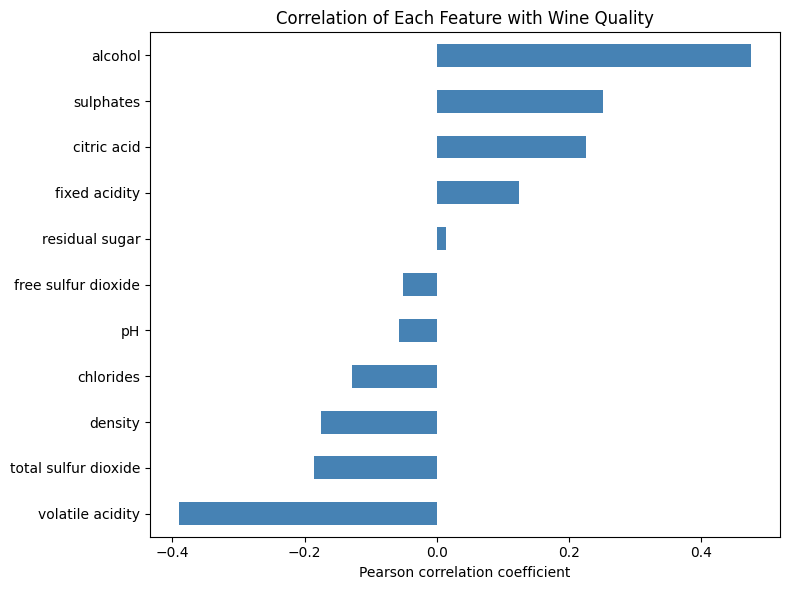

In [ ]:
plt.figure(figsize=(8, 6))
corr_with_target.drop("quality").sort_values().plot(kind="barh", color="steelblue")
plt.title("Correlation of Each Feature with Wine Quality")
plt.xlabel("Pearson correlation coefficient")
plt.tight_layout()
plt.show()

### Principal Component Analysis

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
X_final = df.drop(columns=["quality", "fixed_acidity_dup", "total_so2_scaled"])
X_scaled = StandardScaler().fit_transform(X_final)
pca = PCA()
pca.fit(X_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("--- Principal Component Analysis (PCA) ---")
print("Original number of features:", X_final.shape[1])
print("Reduced components needed to retain 95% variance:", n_components_95)
print("Explained variance ratio per component:", pca.explained_variance_ratio_[:8].round(3))
print(f"Total variance retained with {n_components_95} components: {cumulative_variance[n_components_95 - 1]*100:.2f}%")

--- Principal Component Analysis (PCA) ---
Original number of features: 11
Reduced components needed to retain 95% variance: 9
Explained variance ratio per component: [0.282 0.175 0.141 0.11  0.087 0.06  0.053 0.038]
Total variance retained with 9 components: 97.81%


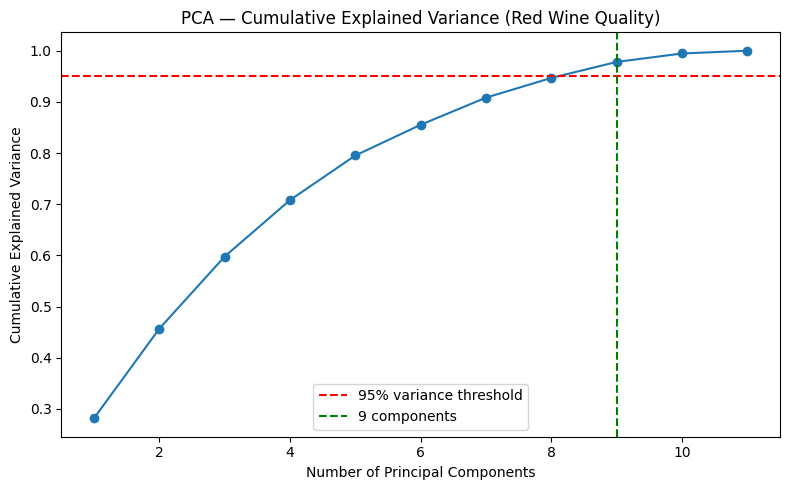

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance threshold")
plt.axvline(n_components_95, color="green", linestyle="--", label=f"{n_components_95} components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Cumulative Explained Variance (Red Wine Quality)")
plt.legend()
plt.tight_layout()
plt.show()